# Empirical `avg_stall_ns` Threshold Calibration — Independent Methods

This notebook uses the **same data loading, cleaning, and feature-engineering steps as `bottleneck_diagnosis_v7(3).ipynb`**, but removes the classifier-selection logic from threshold calibration.

The goal is to estimate a **High-stall boundary from the stall-time data itself**, then compare independent methods:

1. Existing percentile ladder and empirical percentile of 1.5 ms
2. Two-component Gaussian Mixture Model (GMM) intersection
3. KDE density-valley threshold
4. Otsu variance-minimizing threshold
5. One-breakpoint ordered change-point / two-regime variance threshold
6. Robust MAD upper-tail threshold
7. IQR upper-fence threshold
8. Per-session GMM stability analysis
9. Optional performance-degradation breakpoint, **only if an independent outcome column is supplied**

The notebook does **not** train a Random Forest or use precision/recall/F1 to choose the threshold.

> **Important:** the final comparison includes distance from the historical 1.5 ms value so you can see which methods are numerically close. That distance is a diagnostic only; it should not be described in the paper as the scientific selection criterion.

## Methodological rule

The threshold must be estimated from information that is independent of the downstream High-vs-Not-High classifier. Therefore, `avg_stall_ns` itself is used only to **derive the label boundary**, while the classifier's feature set remains leakage-free by continuing to exclude stall-derived columns.

For skewed stall-time data, most distributional methods below operate on:

\[
z = \log(1 + \text{avg\_stall\_ns}).
\]

A threshold found in log space is transformed back to milliseconds before comparison.

In [1]:
# Imports and common configuration
import warnings
warnings.filterwarnings('ignore')

import os
import gc
import json
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import gaussian_kde
from scipy.signal import find_peaks
from scipy.ndimage import gaussian_filter1d
from sklearn.mixture import GaussianMixture

pd.set_option('display.float_format', '{:.4f}'.format)
pd.set_option('display.max_columns', 80)
sns.set_style('whitegrid')

RANDOM_STATE = 42
REFERENCE_THRESHOLD_MS = 1.5
MIN_SESSION_ROWS = 500

# Analysis-size limits keep KDE/GMM/session analysis practical on ~600k+ rows.
GMM_MAX_ROWS = 200_000
KDE_MAX_ROWS = 25_000
SESSION_MAX_ROWS = 50_000

print('Configuration loaded.')
print(f'Historical reference threshold: {REFERENCE_THRESHOLD_MS:.2f} ms')

Configuration loaded.
Historical reference threshold: 1.50 ms


# Section 1 — Same data loading as the existing v7 notebook

The following cells intentionally keep the original manual CSV loading convention:

```python
CSV_PARTS = ['perf_metrics1.csv', 'perf_metrics2.csv']
```

Place this notebook in the same directory where those files are available, or edit `CSV_PARTS` only if your file names/location differ.

In [2]:
# -- Load multiple CSV parts (same approach as v7) ------------------------------
CSV_PARTS = [
    'perf_metrics1.csv',
    'perf_metrics2.csv',
    # add more here as you collect them
]
# -------------------------------------------------------------------------------

dfs = []
for path in CSV_PARTS:
    if not os.path.exists(path):
        print(f'  skipping (not found): {path}')
        continue
    part = pd.read_csv(path)
    part['source_file'] = path
    dfs.append(part)
    print(f'  loaded {path:<20}: {len(part):>8} rows')

if not dfs:
    raise FileNotFoundError(
        'No CSV files were loaded. Put perf_metrics1.csv/perf_metrics2.csv in the notebook directory '
        'or edit CSV_PARTS above.'
    )

df_raw = pd.concat(dfs, ignore_index=True)
print(f'\nCombined shape: {df_raw.shape}')
if 'session_label' in df_raw.columns:
    print(f"Sessions found : {df_raw['session_label'].unique().tolist()}")
    display(df_raw['session_label'].value_counts())

  loaded perf_metrics1.csv   :   526895 rows
  loaded perf_metrics2.csv   :   250683 rows

Combined shape: (777578, 45)
Sessions found : ['idle', 'cpu_low', 'cpu_medium', 'cpu_high', 'cpu_overloaded', 'mem_low', 'mem_high', 'io_low', 'lock_low', 'mixed_load', 'cpu_extreme', 'cpu_ultra', 'mem_extreme', 'mem_thrashing', 'cpu_mem_extreme', 'cpu_mem_ultra', 'io_extreme', 'cpu_io_extreme', 'lock_extreme', 'lock_cpu_mix', 'everything_max', 'everything_insane', 'cpu_2x', 'cpu_4x', 'cpu_8x', 'mem_reclaim', 'mem_heavy_reclaim', 'cpu_mem_2x', 'cpu_mem_4x', 'cpu_mem_8x', 'cpu_mem_io', 'cpu_mem_io_heavy', 'lock_heavy', 'lock_cpu_heavy', 'everything_extreme', 'compile_only', 'compile_sysbench', 'compile_blender', 'full_system', 'mem_swap_thrashing', 'cpu_l3_cache_misses', 'mem_swap_thrash', 'mem_tlb_cache_miss', 'io_async_saturation', 'ctx_flood', 'llm_inference', 'ml_training', 'stream_memory_contention', 'cache_contention', 'context_switch_contention']


session_label
stream_memory_contention     146855
cache_contention             133428
context_switch_contention    121529
llm_inference                 39621
everything_max                21993
ml_training                   21422
everything_insane             20568
lock_cpu_heavy                11752
cpu_8x                        10213
lock_low                      10112
lock_heavy                     9933
everything_extreme             9705
cpu_mem_io                     9449
cpu_medium                     9261
full_system                    8964
cpu_low                        8331
cpu_mem_io_heavy               8082
cpu_mem_4x                     8024
cpu_mem_8x                     7969
mem_low                        7914
mem_extreme                    7764
mem_reclaim                    7449
compile_only                   6823
cpu_mem_2x                     6718
io_low                         6653
compile_sysbench               6585
compile_blender                6570
mem_tlb_cache_

In [3]:
# -- CLEANING (same rules as v6/v7) --------------------------------------------
df = df_raw.copy()
before = len(df)

df = df[df['pid'] > 0]
df = df[df['ctx_switches'] > 0]
df = df[df['latency_count'] > 0]

print(f'Cleaned: {before} -> {len(df)} rows ({before - len(df)} removed)')

Cleaned: 777578 -> 664256 rows (113322 removed)


In [4]:
# -- FEATURE ENGINEERING (same causal signals as v7) ---------------------------
df['involuntary_ratio']  = df['involuntary_switches'] / df['ctx_switches'].clip(lower=1)
df['voluntary_ratio']    = df['voluntary_switches']   / df['ctx_switches'].clip(lower=1)
df['runtime_per_switch'] = df['total_runtime_ns']     / df['ctx_switches'].clip(lower=1)
df['read_write_ratio']   = df['read_bytes'] / (df['write_bytes'] + 1)
df['io_bytes_total']     = df['read_bytes'] + df['write_bytes']
df['alloc_pressure']     = df['total_alloc_bytes'] / df['ctx_switches'].clip(lower=1)
df['lock_pressure']      = (
    df['mutex_contentions'] + df['rwsem_read_contentions'] + df['rwsem_write_contentions']
)

log_cols = ['total_runtime_ns', 'avg_syscall_latency_ns', 'max_syscall_latency_ns',
            'io_bytes_total', 'total_alloc_bytes']
for col in log_cols:
    if col in df.columns:
        df[f'log_{col}'] = np.log1p(df[col])

print(f'Features after engineering: {df.shape[1]} columns')

Features after engineering: 57 columns


In [5]:
# -- Same leakage audit / feature allowlist as v7 -------------------------------
LEAKY_COLS = {
    'avg_stall_ns', 'stall_ns', 'max_stall_ns', 'latency_count',
    'stall_per_switch', 'log_stall_ns', 'log_avg_stall_ns', 'log_max_stall_ns',
    'stall_spike', 'log_stall_spike',
}

ALLOWED_FEATURES = [
    'ctx_switches', 'cpu_migrations', 'involuntary_switches', 'voluntary_switches',
    'involuntary_ratio', 'voluntary_ratio', 'avg_runq_ratio', 'runtime_per_switch',
    'minor_faults', 'major_faults', 'kmalloc_count', 'kfree_count',
    'total_alloc_bytes', 'alloc_pressure',
    'read_count', 'write_count', 'read_bytes', 'write_bytes', 'read_write_ratio', 'io_bytes_total',
    'mutex_contentions', 'avg_mutex_wait_ns', 'rwsem_read_contentions', 'rwsem_write_contentions', 'lock_pressure',
    'syscall_count', 'avg_syscall_latency_ns', 'futex_count',
    'log_total_runtime_ns', 'log_avg_syscall_latency_ns', 'log_max_syscall_latency_ns',
    'log_io_bytes_total', 'log_total_alloc_bytes',
]

FEATURE_COLS = [f for f in ALLOWED_FEATURES if f in df.columns]
leakage_check = set(FEATURE_COLS) & LEAKY_COLS
assert len(leakage_check) == 0, f'LEAKAGE DETECTED: {leakage_check}'
print(f'Leakage check passed -- {len(FEATURE_COLS)} features, none target-derived')

Leakage check passed -- 33 features, none target-derived


# Section 2 — Prepare the threshold variable

All threshold methods below use the measured `avg_stall_ns` column. Rows with missing, non-finite, or negative values are excluded **only from threshold calibration**; the original `df` remains available.

In [6]:
STALL_COL = 'avg_stall_ns'
assert STALL_COL in df.columns, f'{STALL_COL} not found in dataset.'

stall_ns = pd.to_numeric(df[STALL_COL], errors='coerce').to_numpy(dtype='float64')
valid = np.isfinite(stall_ns) & (stall_ns >= 0)
stall_ns = stall_ns[valid]

stall_ms = stall_ns / 1e6
z = np.log1p(stall_ns)

print(f'Valid stall observations: {len(stall_ms):,}')
print(f'Min / median / max (ms): {np.min(stall_ms):.6f} / {np.median(stall_ms):.6f} / {np.max(stall_ms):.6f}')
print(f'Historical 1.5 ms empirical percentile: {100*np.mean(stall_ms <= REFERENCE_THRESHOLD_MS):.3f}%')

Valid stall observations: 664,256
Min / median / max (ms): 0.000601 / 0.159655 / 2612.931489
Historical 1.5 ms empirical percentile: 95.664%


In [7]:
# Deterministic samples used where an O(n^2) or repeated fitting method would be costly.
rng = np.random.default_rng(RANDOM_STATE)

def deterministic_sample(a, max_rows):
    a = np.asarray(a)
    if len(a) <= max_rows:
        return a.copy()
    idx = rng.choice(len(a), size=max_rows, replace=False)
    return a[idx]

z_gmm = deterministic_sample(z, GMM_MAX_ROWS)
z_kde = deterministic_sample(z, KDE_MAX_ROWS)

print(f'GMM observations: {len(z_gmm):,}')
print(f'KDE observations: {len(z_kde):,}')

GMM observations: 200,000
KDE observations: 25,000


# Method 1 — Percentile ladder

This is a descriptive baseline rather than a mechanistic definition. It shows where 1.5 ms lies in the empirical distribution and provides transparent candidate tail cutoffs.

In [8]:
percentiles = [50, 75, 85, 90, 95, 96, 97, 97.5, 98, 99, 99.5, 99.9]
percentile_table = pd.DataFrame({
    'percentile': percentiles,
    'threshold_ms': [np.percentile(stall_ms, p) for p in percentiles],
})

one_point_five_percentile = 100 * np.mean(stall_ms < REFERENCE_THRESHOLD_MS)

print('Percentile ladder:')
display(percentile_table)
print(f'\n1.5 ms is approximately the {one_point_five_percentile:.3f}th percentile of avg_stall_ns.')

Percentile ladder:


,percentile,threshold_ms
0,50.0000,0.1597
1,75.0000,0.4123
2,85.0000,0.5242
3,90.0000,0.6498
4,95.0000,1.1893
5,96.0000,1.7336
6,97.0000,2.7377
7,97.5000,3.3381
8,98.0000,4.0648
9,99.0000,5.7970



1.5 ms is approximately the 95.664th percentile of avg_stall_ns.


# Method 2 — Two-component Gaussian Mixture Model (GMM)

A two-component GMM is fitted to the log-transformed stall-time distribution. The threshold is the **equal-posterior intersection** between the lower-stall and higher-stall components.

This is useful because the threshold corresponds to a transition between two statistically modeled regimes rather than to classifier performance.

In [9]:
def gmm_intersection_threshold(log_values, random_state=RANDOM_STATE):
    x = np.asarray(log_values, dtype='float64').reshape(-1, 1)
    model = GaussianMixture(
        n_components=2,
        covariance_type='full',
        n_init=5,
        random_state=random_state,
    )
    model.fit(x)

    means = model.means_.ravel()
    vars_ = model.covariances_.reshape(2)
    weights = model.weights_.ravel()

    # Sort by mean so component 0 = lower-stall regime, component 1 = higher-stall regime.
    order = np.argsort(means)
    means = means[order]
    vars_ = vars_[order]
    weights = weights[order]
    stds = np.sqrt(vars_)

    # Solve log(weight0*N0) = log(weight1*N1): a*x^2+b*x+c=0.
    a = 1/(2*vars_[1]) - 1/(2*vars_[0])
    b = means[0]/vars_[0] - means[1]/vars_[1]
    c = (means[1]**2)/(2*vars_[1]) - (means[0]**2)/(2*vars_[0]) + np.log((weights[1]*stds[0])/(weights[0]*stds[1]))

    if abs(a) < 1e-14:
        roots = np.array([-c/b])
    else:
        roots = np.roots([a, b, c])
        roots = roots[np.isreal(roots)].real

    between = roots[(roots > means[0]) & (roots < means[1])]
    if len(between) == 0:
        # Fallback to the midpoint if the numerical solution is pathological.
        z_star = float(np.mean(means))
    else:
        z_star = float(between[0])

    # Posterior at the selected point for reporting.
    logdens = []
    for w, m, v in zip(weights, means, vars_):
        logdens.append(np.log(w) - 0.5*np.log(2*np.pi*v) - ((z_star-m)**2)/(2*v))
    mmax = max(logdens)
    post = np.exp(logdens - mmax)
    post = post / post.sum()

    return {
        'threshold_ms': np.expm1(z_star)/1e6,
        'threshold_log': z_star,
        'model': model,
        'means_log': means,
        'stds_log': stds,
        'weights': weights,
        'posterior_at_threshold': post,
    }

gmm_result = gmm_intersection_threshold(z_gmm)
print(f"GMM threshold: {gmm_result['threshold_ms']:.6f} ms")
print(f"Lower component mean (log): {gmm_result['means_log'][0]:.4f}")
print(f"Higher component mean (log): {gmm_result['means_log'][1]:.4f}")
print(f"Component weights: {gmm_result['weights'][0]:.4f}, {gmm_result['weights'][1]:.4f}")
print(f"Posterior at threshold: {gmm_result['posterior_at_threshold'][0]:.4f}, {gmm_result['posterior_at_threshold'][1]:.4f}")

GMM threshold: 0.056829 ms
Lower component mean (log): 8.8377
Higher component mean (log): 12.5904
Component weights: 0.3260, 0.6740
Posterior at threshold: 0.1887, 0.8113


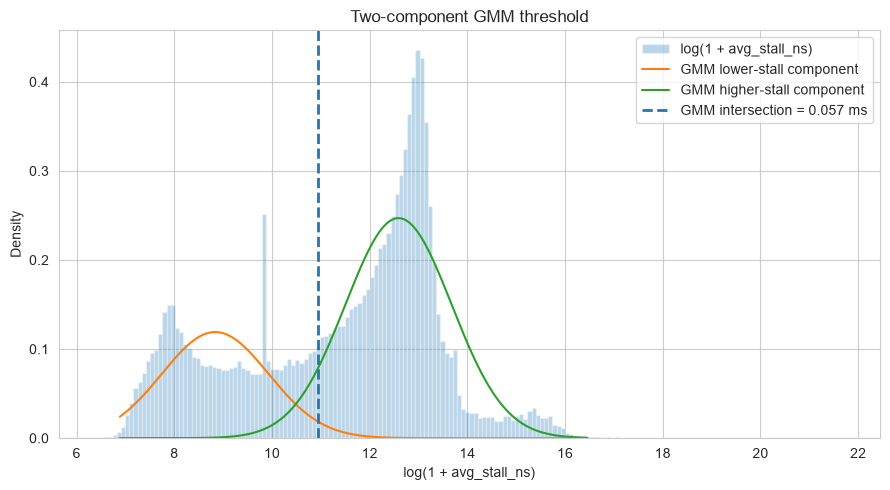

In [10]:
# Plot the fitted GMM and its equal-posterior intersection.
xx = np.linspace(np.percentile(z_gmm, 0.1), np.percentile(z_gmm, 99.9), 1200)
proba = gmm_result['model'].predict_proba(xx.reshape(-1,1))
means = gmm_result['means_log']
weights = gmm_result['weights']
stds = gmm_result['stds_log']

def norm_pdf(x, m, s):
    return np.exp(-0.5*((x-m)/s)**2)/(s*np.sqrt(2*np.pi))

comp0 = weights[0] * norm_pdf(xx, means[0], stds[0])
comp1 = weights[1] * norm_pdf(xx, means[1], stds[1])
threshold_log = gmm_result['threshold_log']

fig, ax = plt.subplots(figsize=(9,5))
ax.hist(z_gmm, bins=180, density=True, alpha=0.30, label='log(1 + avg_stall_ns)')
ax.plot(xx, comp0, label='GMM lower-stall component')
ax.plot(xx, comp1, label='GMM higher-stall component')
ax.axvline(threshold_log, linestyle='--', linewidth=2, label=f"GMM intersection = {gmm_result['threshold_ms']:.3f} ms")
ax.set_xlabel('log(1 + avg_stall_ns)')
ax.set_ylabel('Density')
ax.set_title('Two-component GMM threshold')
ax.legend()
plt.tight_layout()
plt.savefig('01_gmm_threshold.png', dpi=180, bbox_inches='tight')
plt.show()

# Method 3 — KDE density valley

Estimate the stall-time density in log space and locate the **local density minimum between the two dominant density peaks**. If no two-peak structure can be detected, the method is reported as unavailable rather than forcing a threshold.

In [11]:
def kde_density_valley(log_values):
    x = np.asarray(log_values, dtype='float64')
    kde = gaussian_kde(x)
    lo, hi = np.percentile(x, [0.2, 99.8])
    grid = np.linspace(lo, hi, 2500)
    density = kde(grid)

    peaks, _ = find_peaks(density, prominence=max(density)*0.002, distance=30)
    if len(peaks) < 2:
        return {'threshold_ms': np.nan, 'grid': grid, 'density': density, 'peaks': peaks, 'valley_idx': None}

    # Use the two strongest peaks separated in the domain.
    top = peaks[np.argsort(density[peaks])[-2:]]
    top = np.sort(top)
    valley_idx = top[0] + np.argmin(density[top[0]:top[1]+1])

    return {
        'threshold_ms': np.expm1(grid[valley_idx])/1e6,
        'grid': grid,
        'density': density,
        'peaks': top,
        'valley_idx': int(valley_idx),
    }

kde_result = kde_density_valley(z_kde)
if np.isfinite(kde_result['threshold_ms']):
    print(f"KDE density-valley threshold: {kde_result['threshold_ms']:.6f} ms")
else:
    print('KDE could not identify two sufficiently separated density peaks; no valley threshold returned.')

KDE density-valley threshold: 0.010244 ms


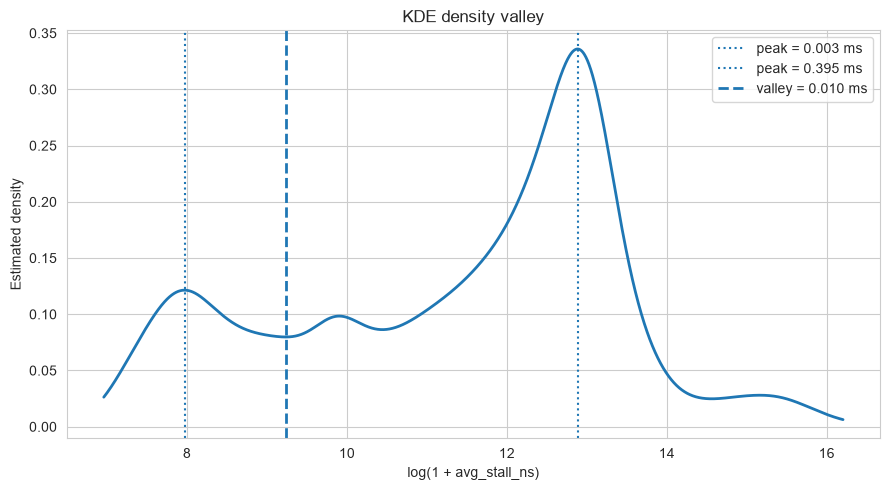

In [12]:
fig, ax = plt.subplots(figsize=(9,5))
ax.plot(kde_result['grid'], kde_result['density'], linewidth=2)
for p in kde_result['peaks']:
    ax.axvline(kde_result['grid'][p], linestyle=':', linewidth=1.5, label=f"peak = {np.expm1(kde_result['grid'][p])/1e6:.3f} ms")
if kde_result['valley_idx'] is not None:
    v = kde_result['valley_idx']
    ax.axvline(kde_result['grid'][v], linestyle='--', linewidth=2, label=f"valley = {kde_result['threshold_ms']:.3f} ms")
ax.set_xlabel('log(1 + avg_stall_ns)')
ax.set_ylabel('Estimated density')
ax.set_title('KDE density valley')
ax.legend()
plt.tight_layout()
plt.savefig('02_kde_valley.png', dpi=180, bbox_inches='tight')
plt.show()

# Method 4 — Otsu threshold

Otsu's method chooses the threshold that minimizes the weighted within-class variance of a histogram. It is completely independent of classifier performance.

In [13]:
def otsu_threshold_from_hist(values, bins=2048):
    values = np.asarray(values, dtype='float64')
    hist, edges = np.histogram(values, bins=bins)
    centers = (edges[:-1] + edges[1:]) / 2

    weight = hist.astype('float64')
    omega = np.cumsum(weight)
    mu = np.cumsum(weight * centers)
    total = omega[-1]
    total_mu = mu[-1]

    valid = (omega > 0) & (omega < total)
    between = np.full_like(centers, -np.inf, dtype='float64')
    between[valid] = ((total_mu*omega[valid] - mu[valid])**2) / (omega[valid]*(total-omega[valid]))
    idx = int(np.argmax(between))
    return float(np.expm1(centers[idx])/1e6), centers[idx], hist, centers, between

ot_result = otsu_threshold_from_hist(z, bins=2048)
print(f'Otsu threshold: {ot_result[0]:.6f} ms')

Otsu threshold: 2192.627926 ms


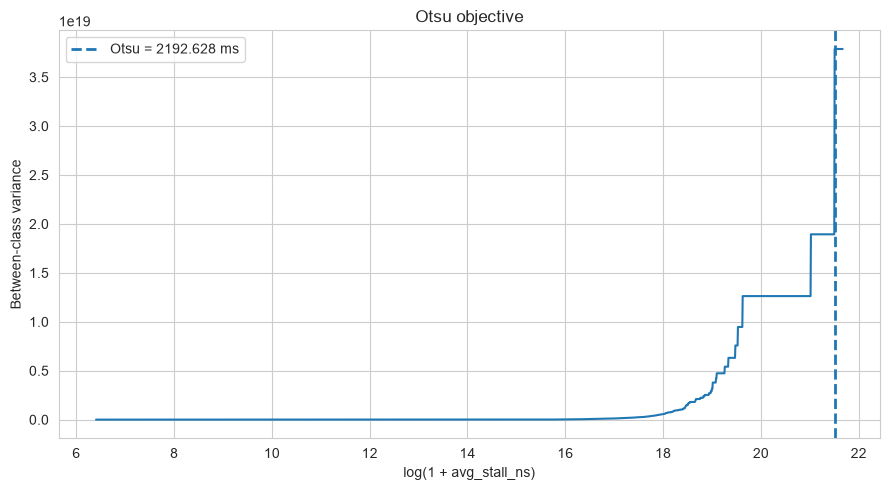

In [14]:
fig, ax = plt.subplots(figsize=(9,5))
ax.plot(ot_result[3], ot_result[4])
ax.axvline(ot_result[1], linestyle='--', linewidth=2, label=f'Otsu = {ot_result[0]:.3f} ms')
ax.set_xlabel('log(1 + avg_stall_ns)')
ax.set_ylabel('Between-class variance')
ax.set_title("Otsu objective")
ax.legend()
plt.tight_layout()
plt.savefig('03_otsu_threshold.png', dpi=180, bbox_inches='tight')
plt.show()

# Method 5 — Ordered two-regime change-point

Sort the log-transformed observations and test candidate cut positions. For each candidate \(k\), compute the total within-regime squared error:

\[
C(k)=\sum_{i\le k}(z_i-\bar z_1)^2+\sum_{i>k}(z_i-\bar z_2)^2.
\]

The minimizing split is the one-breakpoint two-regime variance threshold. A minimum segment fraction prevents the threshold from collapsing into a tiny extreme tail.

In [15]:
def ordered_variance_change_point(values, min_fraction=0.01, max_points=250_000):
    x = np.sort(deterministic_sample(values, max_points).astype('float64'))
    n = len(x)
    lo = max(2, int(np.ceil(n * min_fraction)))
    hi = min(n-2, int(np.floor(n * (1-min_fraction))))
    if hi <= lo:
        return np.nan, None

    # Prefix sums permit O(n) evaluation of the two-segment SSE.
    cs1 = np.cumsum(x)
    cs2 = np.cumsum(x*x)
    total1 = cs1[-1]
    total2 = cs2[-1]
    k = np.arange(lo, hi+1)

    sum1 = cs1[k-1]
    ss1 = cs2[k-1] - (sum1**2)/k
    sum2 = total1 - sum1
    n2 = n-k
    ss2 = (total2 - cs2[k-1]) - (sum2**2)/n2
    cost = ss1 + ss2
    best = int(np.argmin(cost))
    k_star = int(k[best])

    # Use the midpoint between the adjacent sorted observations as threshold.
    threshold_log = float((x[k_star-1] + x[k_star]) / 2)
    threshold_ms = float(np.expm1(threshold_log)/1e6)
    return threshold_ms, {'x':x, 'k':k_star, 'cost':cost, 'candidate_k':k}

cp_threshold_ms, cp_aux = ordered_variance_change_point(z)
print(f'Ordered two-regime change-point threshold: {cp_threshold_ms:.6f} ms')

Ordered two-regime change-point threshold: 0.048354 ms


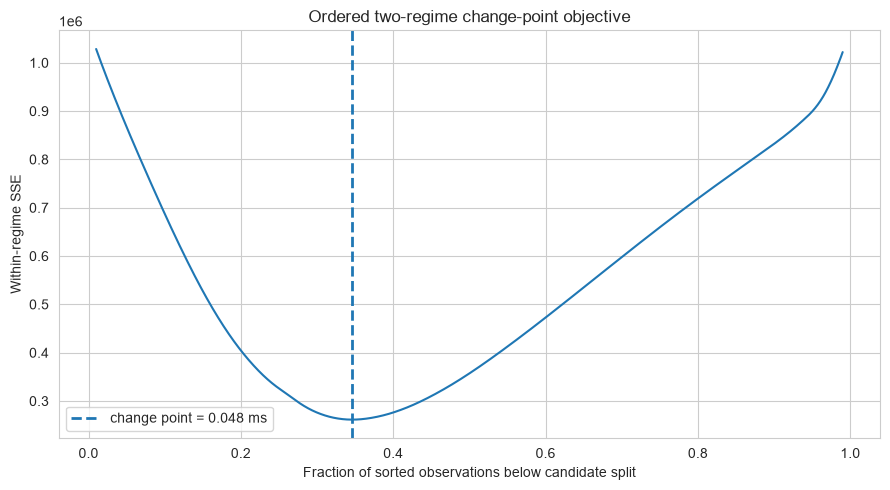

In [16]:
fig, ax = plt.subplots(figsize=(9,5))
ax.plot(cp_aux['candidate_k']/len(cp_aux['x']), cp_aux['cost'], linewidth=1.5)
ax.axvline(cp_aux['k']/len(cp_aux['x']), linestyle='--', linewidth=2, label=f'change point = {cp_threshold_ms:.3f} ms')
ax.set_xlabel('Fraction of sorted observations below candidate split')
ax.set_ylabel('Within-regime SSE')
ax.set_title('Ordered two-regime change-point objective')
ax.legend()
plt.tight_layout()
plt.savefig('04_change_point.png', dpi=180, bbox_inches='tight')
plt.show()

# Method 6 — Robust MAD upper-tail threshold

Define an unusually high stall as a robust upper-tail observation in log space:

\[
\tau = \exp\left(\operatorname{median}(z)+k\cdot1.4826\operatorname{MAD}(z)\right)-1.
\]

The default \(k=3\) is shown explicitly so the assumption is visible and reproducible.

In [17]:
def mad_threshold(values, k=3.0):
    x = np.asarray(values, dtype='float64')
    med = np.median(x)
    mad = np.median(np.abs(x-med))
    robust_sd = 1.4826 * mad
    z_star = med + k * robust_sd
    return float(np.expm1(z_star)/1e6), med, mad

mad_threshold_ms, mad_med, mad_raw = mad_threshold(z, k=3.0)
print(f'MAD threshold (k=3): {mad_threshold_ms:.6f} ms')
print(f'log-space median: {mad_med:.6f}')
print(f'raw MAD: {mad_raw:.6f}')

MAD threshold (k=3): 30.630844 ms
log-space median: 11.980777
raw MAD: 1.181874


# Method 7 — IQR upper fence

A second robust rule uses the classical upper Tukey fence:

\[
\tau = Q_3(z)+1.5\,IQR(z).
\]

It is included separately from MAD because it makes a different distributional assumption about what constitutes an unusually high observation.

In [18]:
q1, q3 = np.percentile(z, [25, 75])
iqr = q3 - q1
iqr_z = q3 + 1.5*iqr
iqr_threshold_ms = float(np.expm1(iqr_z)/1e6)
print(f'IQR upper-fence threshold: {iqr_threshold_ms:.6f} ms')

IQR upper-fence threshold: 44.359562 ms


# Method 8 — Per-session stability using the same GMM criterion

A useful threshold should not arise from one unusual session. For each `session_label`, the notebook fits the same two-component GMM criterion and reports the resulting threshold. Session labels are used only as grouping identifiers; they are **not** interpreted as semantic workload classes here.

The aggregate stability statistic is the median session threshold, with the interquartile range shown explicitly.

In [19]:
session_records = []
if 'session_label' not in df.columns:
    print('session_label is unavailable; skipping per-session stability.')
else:
    valid_df = df.loc[valid, ['session_label', STALL_COL]].copy()
    valid_df[STALL_COL] = pd.to_numeric(valid_df[STALL_COL], errors='coerce')
    valid_df = valid_df.dropna()
    valid_df['z'] = np.log1p(valid_df[STALL_COL].clip(lower=0))

    for session_name, grp in valid_df.groupby('session_label', sort=True):
        if len(grp) < MIN_SESSION_ROWS:
            continue
        zz = deterministic_sample(grp['z'].to_numpy(), SESSION_MAX_ROWS)
        try:
            res = gmm_intersection_threshold(zz, random_state=RANDOM_STATE)
            session_records.append({
                'session_label': session_name,
                'rows': len(grp),
                'threshold_ms': res['threshold_ms'],
            })
        except Exception as e:
            session_records.append({
                'session_label': session_name,
                'rows': len(grp),
                'threshold_ms': np.nan,
            })

    session_results = pd.DataFrame(session_records).dropna(subset=['threshold_ms'])
    display(session_results.sort_values('threshold_ms'))

    if len(session_results):
        med = session_results['threshold_ms'].median()
        q25, q75 = session_results['threshold_ms'].quantile([0.25, 0.75])
        print(f'\nSession-GMM median threshold: {med:.6f} ms')
        print(f'Session-GMM IQR: [{q25:.6f}, {q75:.6f}] ms')
        print(f'Sessions analyzed: {len(session_results)}')
    else:
        print('No session produced a valid GMM threshold.')

,session_label,rows,threshold_ms
46,mem_tlb_cache_miss,6054,0.0022
32,llm_inference,33707,0.0031
30,io_extreme,5440,0.0033
27,full_system,7258,0.0045
43,mem_swap_thrash,862,0.0049
35,lock_extreme,3517,0.0050
38,mem_extreme,6939,0.0054
42,mem_reclaim,6403,0.0055
2,compile_only,5261,0.0056
3,compile_sysbench,5078,0.0057



Session-GMM median threshold: 0.079298 ms
Session-GMM IQR: [0.006727, 0.137848] ms
Sessions analyzed: 50


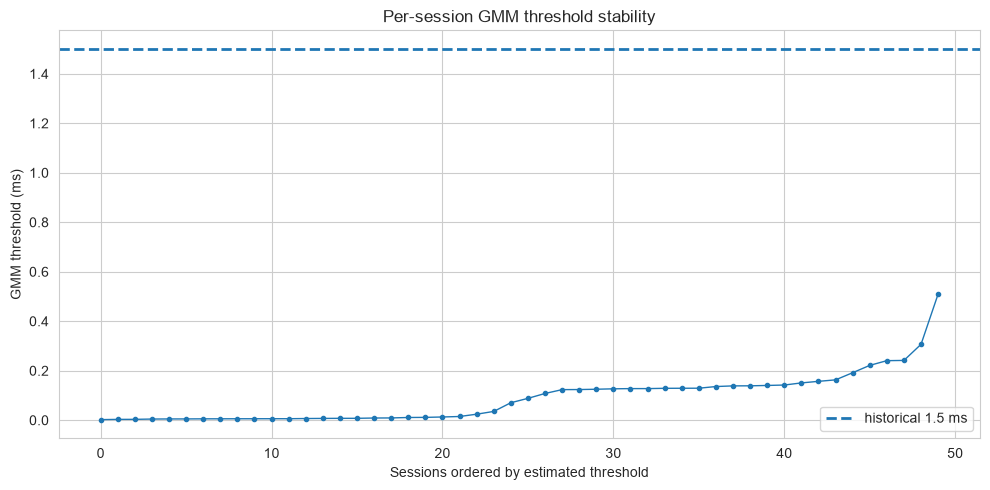

In [20]:
if 'session_results' in globals() and len(session_results):
    fig, ax = plt.subplots(figsize=(10,5))
    s = session_results.sort_values('threshold_ms')
    ax.plot(np.arange(len(s)), s['threshold_ms'].to_numpy(), marker='o', markersize=3, linewidth=1)
    ax.axhline(REFERENCE_THRESHOLD_MS, linestyle='--', linewidth=2, label='historical 1.5 ms')
    ax.set_xlabel('Sessions ordered by estimated threshold')
    ax.set_ylabel('GMM threshold (ms)')
    ax.set_title('Per-session GMM threshold stability')
    ax.legend()
    plt.tight_layout()
    plt.savefig('05_session_gmm_stability.png', dpi=180, bbox_inches='tight')
    plt.show()

# Method 9 — Optional operational performance-degradation breakpoint

This method is intentionally **not inferred from `total_runtime_ns` or another proxy automatically**. The performance outcome must be an independent quantity that has a clear interpretation, such as application throughput, end-to-end latency, or completion time measured at the workload level.

Set `PERFORMANCE_METRIC_COL` below only when such a column exists in your CSVs. The notebook then fits a two-segment linear model in log stall time and searches for a breakpoint where the post-break slope is adverse:

- latency/duration metric: adverse slope = positive
- throughput/rate metric: adverse slope = negative

This is the strongest method when you have a genuine independent outcome, because the threshold then corresponds to observed performance degradation rather than just a distributional boundary.

In [26]:
# Fill this only if your dataset contains an independent workload-level outcome.
PERFORMANCE_METRIC_COL = None   # e.g. 'application_latency_ms'
METRIC_HIGHER_IS_WORSE = True   # True for latency/duration; False for throughput/rate


def operational_breakpoint(df_in, x_col, y_col, higher_is_worse=True, min_fraction=0.05):
    d = df_in[[x_col, y_col]].copy()
    d[x_col] = pd.to_numeric(d[x_col], errors='coerce')
    d[y_col] = pd.to_numeric(d[y_col], errors='coerce')
    d = d.replace([np.inf, -np.inf], np.nan).dropna()
    d = d[(d[x_col] >= 0)]
    if len(d) < 500:
        return None, d

    x = np.log1p(d[x_col].to_numpy(dtype='float64'))
    y = d[y_col].to_numpy(dtype='float64')
    if not higher_is_worse:
        y = -y

    order = np.argsort(x)
    x, y = x[order], y[order]
    n = len(x)
    lo = max(20, int(n*min_fraction))
    hi = min(n-20, int(n*(1-min_fraction)))
    candidates = np.linspace(lo, hi, 120, dtype=int)
    candidates = np.unique(candidates)

    def fit_line(xv, yv):
        A = np.column_stack([np.ones(len(xv)), xv])
        coef, *_ = np.linalg.lstsq(A, yv, rcond=None)
        pred = A @ coef
        sse = float(np.sum((yv-pred)**2))
        return coef, sse

    rows=[]
    for k in candidates:
        c1, sse1 = fit_line(x[:k], y[:k])
        c2, sse2 = fit_line(x[k:], y[k:])
        rows.append((k, sse1+sse2, c1[1], c2[1]))
    grid = pd.DataFrame(rows, columns=['k','sse','slope_before','slope_after'])

    # We require an adverse post-break slope after transforming throughput to -throughput.
    adverse = grid['slope_after'] > 0
    if not adverse.any():
        return None, grid.assign(threshold_ms=np.nan)

    g = grid[adverse].sort_values('sse').iloc[0]
    k = int(g['k'])
    z_star = float((x[k-1] + x[k])/2)
    threshold_ms = float(np.expm1(z_star)/1e6)
    grid['threshold_ms'] = np.nan
    grid.loc[grid['k']==k, 'threshold_ms'] = threshold_ms
    return threshold_ms, grid

if PERFORMANCE_METRIC_COL is None:
    numeric_candidates = [c for c in df.columns if pd.api.types.is_numeric_dtype(df[c])]
    blocked = {'pid','cpu','ctx_switches','avg_stall_ns','stall_ns','max_stall_ns'}
    candidates = [c for c in numeric_candidates if c not in blocked]
    print('Operational breakpoint skipped because PERFORMANCE_METRIC_COL is None.')
    print('\nPotential numeric columns you can inspect for an independent outcome:')
    print(candidates)
    operational_threshold_ms = np.nan
    operational_grid = None
else:
    if PERFORMANCE_METRIC_COL not in df.columns:
        raise KeyError(f'{PERFORMANCE_METRIC_COL!r} is not in df.columns')
    operational_threshold_ms, operational_grid = operational_breakpoint(
        df, STALL_COL, PERFORMANCE_METRIC_COL,
        higher_is_worse=METRIC_HIGHER_IS_WORSE,
    )
    print(f'Operational breakpoint: {operational_threshold_ms} ms')
    if operational_grid is not None:
        display(operational_grid.sort_values('sse').head(10))

Operational breakpoint skipped because PERFORMANCE_METRIC_COL is None.

Potential numeric columns you can inspect for an independent outcome:
['timestamp_ns', 'voluntary_switches', 'involuntary_switches', 'cpu_migrations', 'total_runtime_ns', 'latency_count', 'avg_runq_ratio', 'minor_faults', 'major_faults', 'kmalloc_count', 'kfree_count', 'total_alloc_bytes', 'total_free_bytes', 'large_page_allocs', 'syscall_count', 'avg_syscall_latency_ns', 'max_syscall_latency_ns', 'read_count', 'write_count', 'read_bytes', 'write_bytes', 'mmap_count', 'futex_count', 'avg_futex_latency_ns', 'epoll_count', 'avg_epoll_latency_ns', 'poll_count', 'syscall_error_count', 'mutex_contentions', 'avg_mutex_wait_ns', 'max_mutex_wait_ns', 'rwsem_read_contentions', 'avg_rwsem_read_wait_ns', 'rwsem_write_contentions', 'avg_rwsem_write_wait_ns', 'max_rwsem_write_wait_ns', 'involuntary_ratio', 'voluntary_ratio', 'runtime_per_switch', 'read_write_ratio', 'io_bytes_total', 'alloc_pressure', 'lock_pressure', 'log_tota

# Final comparison — all threshold candidates

The table below puts all methods on the same scale. `distance_from_1.5_ms` is included because the historical implementation used 1.5 ms; it is **not** a scientific ranking criterion.

In [22]:
results = [
    {'method':'Percentile p95', 'threshold_ms':float(np.percentile(stall_ms,95)), 'basis':'empirical percentile'},
    {'method':'Percentile p96', 'threshold_ms':float(np.percentile(stall_ms,96)), 'basis':'empirical percentile'},
    {'method':'Percentile p97', 'threshold_ms':float(np.percentile(stall_ms,97)), 'basis':'empirical percentile'},
    {'method':'Percentile p97.5', 'threshold_ms':float(np.percentile(stall_ms,97.5)), 'basis':'empirical percentile'},
    {'method':'Percentile p98', 'threshold_ms':float(np.percentile(stall_ms,98)), 'basis':'empirical percentile'},
    {'method':'GMM intersection', 'threshold_ms':gmm_result['threshold_ms'], 'basis':'equal posterior of 2 log-space regimes'},
    {'method':'KDE density valley', 'threshold_ms':kde_result['threshold_ms'], 'basis':'local minimum between dominant density peaks'},
    {'method':'Otsu', 'threshold_ms':ot_result[0], 'basis':'minimum weighted within-class variance'},
    {'method':'Ordered change-point', 'threshold_ms':cp_threshold_ms, 'basis':'minimum two-regime within-segment SSE'},
    {'method':'MAD k=3', 'threshold_ms':mad_threshold_ms, 'basis':'robust upper-tail cutoff'},
    {'method':'IQR upper fence', 'threshold_ms':iqr_threshold_ms, 'basis':'Q3 + 1.5 IQR in log space'},
]

if 'session_results' in globals() and len(session_results):
    results.append({
        'method':'Session-GMM median',
        'threshold_ms':float(session_results['threshold_ms'].median()),
        'basis':'median of independent per-session GMM thresholds',
    })

if np.isfinite(operational_threshold_ms):
    results.append({
        'method':'Operational breakpoint',
        'threshold_ms':float(operational_threshold_ms),
        'basis':'segmented regression against independent performance outcome',
    })

comparison = pd.DataFrame(results)
comparison['distance_from_1.5_ms'] = (comparison['threshold_ms'] - REFERENCE_THRESHOLD_MS).abs()
comparison['relative_difference_pct'] = 100 * comparison['distance_from_1.5_ms'] / REFERENCE_THRESHOLD_MS
comparison = comparison.sort_values('distance_from_1.5_ms')

display(comparison.style.format({
    'threshold_ms':'{:.4f}',
    'distance_from_1.5_ms':'{:.4f}',
    'relative_difference_pct':'{:.2f}%',
}))

comparison.to_csv('threshold_method_comparison.csv', index=False)
print("Saved: threshold_method_comparison.csv")

,method,threshold_ms,basis,distance_from_1.5_ms,relative_difference_pct
1,Percentile p96,1.7336,empirical percentile,0.2336,15.57%
0,Percentile p95,1.1893,empirical percentile,0.3107,20.71%
2,Percentile p97,2.7377,empirical percentile,1.2377,82.52%
11,Session-GMM median,0.0793,median of independent per-session GMM thresholds,1.4207,94.71%
5,GMM intersection,0.0568,equal posterior of 2 log-space regimes,1.4432,96.21%
8,Ordered change-point,0.0484,minimum two-regime within-segment SSE,1.4516,96.78%
6,KDE density valley,0.0102,local minimum between dominant density peaks,1.4898,99.32%
3,Percentile p97.5,3.3381,empirical percentile,1.8381,122.54%
4,Percentile p98,4.0648,empirical percentile,2.5648,170.98%
9,MAD k=3,30.6308,robust upper-tail cutoff,29.1308,1942.06%


Saved: threshold_method_comparison.csv


# Stability / consensus view

A useful secondary check is whether several **independent** methods converge to a narrow region. This is more informative than taking the method closest to 1.5 ms in isolation.

In [23]:
# Distributional methods only: exclude arbitrary percentile baselines and optional operational result.
consensus_methods = [
    'GMM intersection', 'KDE density valley', 'Otsu',
    'Ordered change-point', 'MAD k=3', 'IQR upper fence', 'Session-GMM median'
]
cons = comparison[comparison['method'].isin(consensus_methods)].copy()
cons = cons[np.isfinite(cons['threshold_ms'])]

if len(cons):
    print('Independent-method consensus:')
    print(f"  median = {cons['threshold_ms'].median():.4f} ms")
    print(f"  IQR    = [{cons['threshold_ms'].quantile(.25):.4f}, {cons['threshold_ms'].quantile(.75):.4f}] ms")
    print(f"  range  = [{cons['threshold_ms'].min():.4f}, {cons['threshold_ms'].max():.4f}] ms")
else:
    print('No independent-method consensus could be computed.')

Independent-method consensus:
  median = 0.0793 ms
  IQR    = [0.0526, 37.4952] ms
  range  = [0.0102, 2192.6279] ms


# Suggested paper evidence to record

After running the notebook, record the **actual numerical outputs** rather than selecting a value in advance.

For a purely distributional justification, the most concise paper statement is likely to use the GMM/KDE/consensus result, for example:

> “The High-stall boundary was calibrated independently of the classifier by modeling the log-transformed average stall-time distribution as separate low- and high-stall regimes. The resulting transition point was approximately **X ms**, and remained stable across execution sessions; hence, **X ms** was adopted as the fixed High-stall threshold.”

If the operational breakpoint is available and agrees with the distributional result, that is stronger:

> “The threshold was selected at the empirically observed stall-time breakpoint, where an independent performance metric showed sustained degradation, with the distributional regime boundary providing consistent support.”

Do not state that the threshold was selected because it maximized Random Forest accuracy, precision, recall, F1, PR-AUC, or any other downstream model metric.

In [24]:
# Optional: one-row export containing the values most useful for the paper draft.
summary_rows = []
summary_rows.append({'item':'Historical threshold', 'value_ms':REFERENCE_THRESHOLD_MS})
for method in ['GMM intersection','KDE density valley','Otsu','Ordered change-point','MAD k=3','IQR upper fence','Session-GMM median','Operational breakpoint']:
    q = comparison.loc[comparison['method']==method, 'threshold_ms']
    if len(q) and np.isfinite(q.iloc[0]):
        summary_rows.append({'item':method, 'value_ms':float(q.iloc[0])})

paper_summary = pd.DataFrame(summary_rows)
display(paper_summary)
paper_summary.to_csv('threshold_paper_summary.csv', index=False)
print('Saved: threshold_paper_summary.csv')

,item,value_ms
0,Historical threshold,1.5000
1,GMM intersection,0.0568
2,KDE density valley,0.0102
3,Otsu,2192.6279
4,Ordered change-point,0.0484
5,MAD k=3,30.6308
6,IQR upper fence,44.3596
7,Session-GMM median,0.0793


Saved: threshold_paper_summary.csv
